# 04 — Explaining the forecast with SHAP

Notebook 03 ranked features by LightGBM *gain*, which says how often a feature is useful for splits but not **how** it moves the forecast or in which direction. SHAP values split each individual prediction into additive contributions (in MW) from every feature, so we can ask:

- Which features move the 2025 forecasts the most?
- How much comes from recent demand (lags) vs weather vs the calendar?
- What shape does the learned temperature effect take?

The model is rebuilt exactly as in notebook 03 (same features, parameters, early-stopping on 2024, refit on 2019–2024) and explained on the 2025 test year.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import lightgbm as lgb
import shap

from src.data import build_dataset
from src.features import make_features, FEATURES

d = make_features(build_dataset())
train, valid, test = d.loc[:"2023"], d.loc["2024"], d.loc["2025"]
train_full = d.loc[:"2024"]

params = dict(learning_rate=0.05, num_leaves=31, subsample=0.8, subsample_freq=1,
              colsample_bytree=0.8, verbose=-1, random_state=42)
gbm = lgb.LGBMRegressor(n_estimators=3000, **params)
gbm.fit(train[FEATURES], train["demand_mw"], eval_set=[(valid[FEATURES], valid["demand_mw"])],
        callbacks=[lgb.early_stopping(100, verbose=False)])
gbm_final = lgb.LGBMRegressor(n_estimators=int(gbm.best_iteration_ * 1.1), **params)
gbm_final.fit(train_full[FEATURES], train_full["demand_mw"])

X_test, y_test = test[FEATURES], test["demand_mw"]
pred = gbm_final.predict(X_test)
print(f"2025 test MAPE: {(np.abs(pred - y_test) / y_test).mean() * 100:.2f}%  (same model as notebook 03)")

/usr/local/lib/python3.13/dist-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


2025 test MAPE: 2.63%  (same model as notebook 03)


## SHAP values on the 2025 test year (8,760 hours)

In [2]:
explainer = shap.TreeExplainer(gbm_final)
sv = explainer(X_test)
# sanity check: base value + contributions reproduce the model output
print("max |base + sum(SHAP) - prediction| =", f"{np.abs(sv.values.sum(1) + sv.base_values - pred).max():.4f} MW")
print(f"base value (average training prediction): {float(np.ravel(sv.base_values)[0]):,.0f} MW")

max |base + sum(SHAP) - prediction| = 0.0000 MW
base value (average training prediction): 15,513 MW


In [3]:
mean_abs = pd.Series(np.abs(sv.values).mean(0), index=FEATURES).sort_values(ascending=False)
mean_abs.round(0).to_frame("mean |SHAP| (MW)").head(10)

,mean |SHAP| (MW)
lag_24,1176.0
hour,375.0
temp_c,316.0
dow,265.0
lag_168,216.0
prev_day_max,207.0
temp_day_mean,141.0
hdd,136.0
temp_prev_day_mean,128.0
rh_pct,98.0


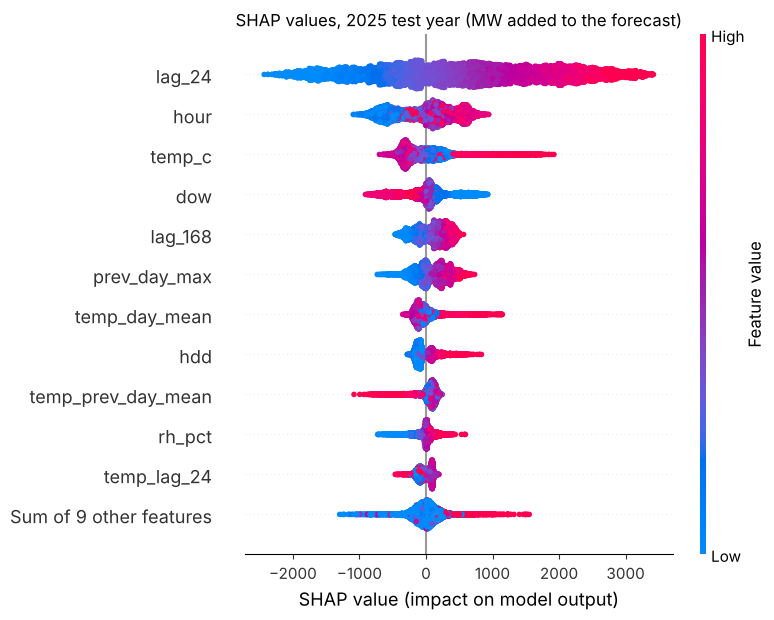

In [4]:
shap.plots.beeswarm(sv, max_display=12, show=False)
plt.title("SHAP values, 2025 test year (MW added to the forecast)")
plt.tight_layout(); plt.savefig("figures/shap_summary_2025.png", dpi=130, bbox_inches="tight")
plt.show()

## Lags vs weather vs calendar

Summing |SHAP| by feature group shows where the forecast's movement away from the average comes from.

In [5]:
groups = {
    "Recent demand (lags)": ["lag_24", "lag_48", "lag_168", "prev_day_mean", "prev_day_max"],
    "Weather": ["temp_c", "hdd", "cdd", "rh_pct", "cloud_pct", "temp_day_mean", "temp_prev_day_mean", "temp_lag_24"],
    "Calendar": ["hour", "dow", "month", "is_weekend", "is_holiday", "doy_sin", "doy_cos"],
}
assert sorted(sum(groups.values(), [])) == sorted(FEATURES)
group_share = pd.Series({g: mean_abs[f].sum() for g, f in groups.items()})
group_share = (group_share / group_share.sum() * 100).round(1)
group_share.to_frame("share of total |SHAP| (%)")

,share of total |SHAP| (%)
Recent demand (lags),47.3
Weather,29.0
Calendar,23.7


## Learned temperature effect

Combined SHAP contribution of all same-day temperature features (`temp_c`, `hdd`, `cdd`, `temp_day_mean`), plotted against the daily mean temperature. This is the model's version of the U-shape seen in notebook 02.

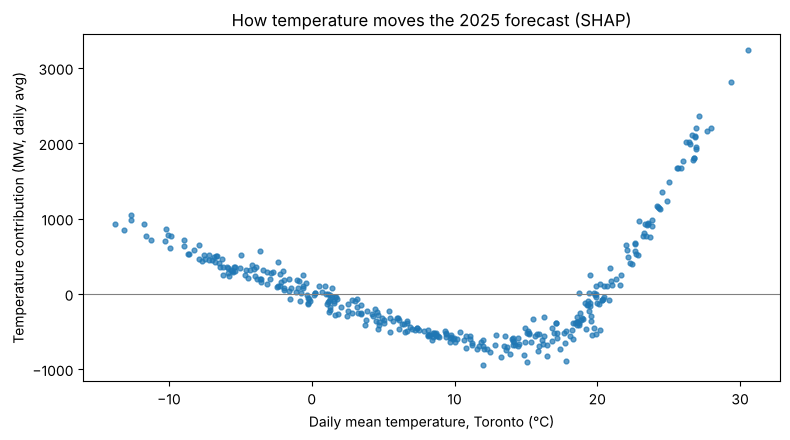

,mean,count
temp_day_mean,,
"(-30, -10]",860.0,10
"(-10, 0]",280.0,85
"(0, 10]",-323.0,100
"(10, 15]",-665.0,38
"(15, 20]",-404.0,66
"(20, 25]",518.0,44
"(25, 35]",2037.0,22


In [6]:
temp_feats = ["temp_c", "hdd", "cdd", "temp_day_mean"]
idx = [FEATURES.index(f) for f in temp_feats]
temp_effect = pd.Series(sv.values[:, idx].sum(1), index=X_test.index)
daily = pd.DataFrame({"temp_day_mean": X_test["temp_day_mean"].resample("D").first(),
                      "temp_effect_mw": temp_effect.resample("D").mean()})

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.scatter(daily["temp_day_mean"], daily["temp_effect_mw"], s=12, alpha=0.7)
ax.axhline(0, color="grey", lw=0.8)
ax.set(xlabel="Daily mean temperature, Toronto (°C)", ylabel="Temperature contribution (MW, daily avg)",
       title="How temperature moves the 2025 forecast (SHAP)")
fig.tight_layout(); fig.savefig("figures/shap_temperature_2025.png", dpi=130)
plt.show()

bins = pd.cut(daily["temp_day_mean"], [-30, -10, 0, 10, 15, 20, 25, 35])
daily.groupby(bins, observed=True)["temp_effect_mw"].agg(["mean", "count"]).round(0)

In [7]:
coolest = daily["temp_effect_mw"].idxmin()
hottest = daily["temp_day_mean"].idxmax()
print(f"Lowest temperature contribution: {daily.loc[coolest, 'temp_effect_mw']:,.0f} MW at {daily.loc[coolest, 'temp_day_mean']:.1f} °C ({coolest.date()})")
print(f"Hottest day {hottest.date()} ({daily.loc[hottest, 'temp_day_mean']:.1f} °C): {daily.loc[hottest, 'temp_effect_mw']:+,.0f} MW")
coldest = daily["temp_day_mean"].idxmin()
print(f"Coldest day {coldest.date()} ({daily.loc[coldest, 'temp_day_mean']:.1f} °C): {daily.loc[coldest, 'temp_effect_mw']:+,.0f} MW")

Lowest temperature contribution: -949 MW at 12.0 °C (2025-10-08)
Hottest day 2025-06-24 (30.6 °C): +3,235 MW
Coldest day 2025-01-21 (-13.8 °C): +933 MW


## Takeaways (2025 test year)

- **Yesterday's demand is the backbone of the forecast.** `lag_24` (same hour yesterday) has a mean |SHAP| of 1,176 MW, about three times the next feature (`hour`, 375 MW). Recent-demand features together account for 47% of the total |SHAP|, weather 29% and calendar 24%.
- **The model learned the U-shaped temperature response, and it is lopsided.** The combined temperature contribution is lowest around a 12 °C daily mean (−949 MW). On the coldest 2025 day (−13.8 °C) it adds +933 MW; on the hottest (30.6 °C) it adds +3,235 MW. Days above 25 °C average +2,037 MW versus +860 MW for days below −10 °C, so cooling load moves the forecast far more than heating load (much of Ontario's heating is gas, not electric).
- **Weather works as a correction on top of persistence.** A warm *previous* day (`temp_prev_day_mean`) pushes the forecast down while a warm *forecast* day (`temp_c`, `temp_day_mean`) pushes it up. Since `lag_24` already carries yesterday's weather, the model in effect removes yesterday's temperature effect and adds today's, which is how it anticipates cold snaps and heat waves that persistence misses. Weekends (`dow` = 5, 6) pull the forecast down by 435 MW on average (up to 910 MW).
